In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
np.random.seed(42)

n = 2000

data = pd.DataFrame({
    "income": np.random.randint(15000, 150001, n),
    "debt": np.random.randint(0, 80001, n),
    "payment_history": np.random.randint(0, 11, n),
    "credit_utilization": np.random.uniform(0, 1, n),
    "employment_years": np.random.randint(0, 21, n)
})

data["creditworthy"] = (
    (data["income"] > data["debt"] * 1.5) &
    (data["payment_history"] >= 6) &
    (data["credit_utilization"] < 0.75)
).astype(int)

print(data.head())
print("\nDataset size:", data.shape)
print("\nClass counts:")
print(data["creditworthy"].value_counts())

   income   debt  payment_history  credit_utilization  employment_years  \
0  136958  49811                4            0.617194                17   
1  146932  30447                7            0.969819                11   
2  118694  30254                1            0.727631                15   
3  134879  57418                8            0.922604                 4   
4  125268  14472                5            0.762212                19   

   creditworthy  
0             0  
1             0  
2             0  
3             0  
4             0  

Dataset size: (2000, 6)

Class counts:
creditworthy
0    1535
1     465
Name: count, dtype: int64


In [3]:
X = data.drop("creditworthy", axis=1)
y = data["creditworthy"]

print("Input features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input features:
   income   debt  payment_history  credit_utilization  employment_years
0  136958  49811                4            0.617194                17
1  146932  30447                7            0.969819                11
2  118694  30254                1            0.727631                15
3  134879  57418                8            0.922604                 4
4  125268  14472                5            0.762212                19

Target:
0    0
1    0
2    0
3    0
4    0
Name: creditworthy, dtype: int64


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 1600
Testing records: 400


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Credit scoring model trained successfully!")

Credit scoring model trained successfully!


In [6]:
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Precision:", round(precision_score(y_test, y_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred, zero_division=0), 4))
print("F1 Score:", round(f1_score(y_test, y_pred, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Accuracy: 0.87
Precision: 0.7412
Recall: 0.6774
F1 Score: 0.7079
ROC-AUC: 0.9379

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.93      0.92       307
           1       0.74      0.68      0.71        93

    accuracy                           0.87       400
   macro avg       0.82      0.80      0.81       400
weighted avg       0.87      0.87      0.87       400



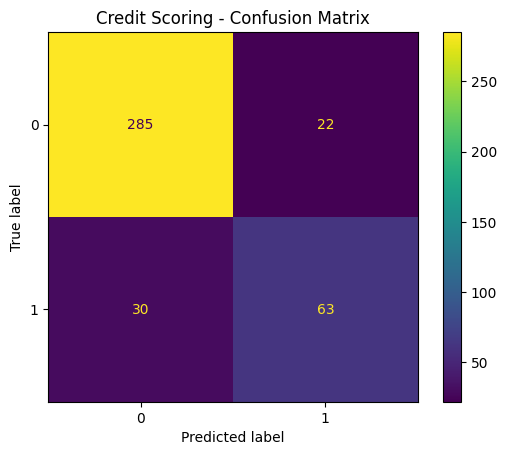

In [7]:
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)

plt.title("Credit Scoring - Confusion Matrix")
plt.show()

In [ ]:
RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("Credit Scoring - ROC Curve")
plt.show()

In [ ]:
new_applicant = pd.DataFrame([{
    "income": 80000,
    "debt": 20000,
    "payment_history": 9,
    "credit_utilization": 0.30,
    "employment_years": 5
}])

new_scaled = scaler.transform(new_applicant)

prediction = model.predict(new_scaled)[0]
probability = model.predict_proba(new_scaled)[0][1]

print("Predicted class:", prediction)
print("Estimated probability:", round(probability * 100, 2), "%")

if prediction == 1:
    print("Result: Creditworthy under the sample model")
else:
    print("Result: Not creditworthy under the sample model")

In [8]:
import joblib

joblib.dump(
    {"model": model, "scaler": scaler},
    "credit_scoring_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [9]:
from google.colab import files

files.download("credit_scoring_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>